# Lecture 31: Least Squares
v.ekc

Why is the regression line the *best* line? Today we define "best" (smallest root mean squared error), meet `minimize`, and discover that the formulas from last lecture win the optimization, then break free of lines entirely.

**Today's sections:**
1. Slope and intercept, recapped
2. Error in estimation
3. Root mean square error
4. Numerical optimization
5. Nonlinear regression

In [1]:
# imports
from datascience import *
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

> **Setup cells:** the next few cells define plotting helpers and the regression functions from Lecture 30, run them and move on.

In [2]:
# Some functions for plotting. You don't have to understand how any
# of the functions in this cell work, since they use things we 
# haven't learned about in Data 111.

def resize_window(lim=3.5):
    plots.xlim(-lim, lim)
    plots.ylim(-lim, lim)
    
def draw_line(slope=0, intercept=0, x=make_array(-4, 4), color='r'):
    y = x*slope + intercept
    plots.plot(x, y, color=color)
    
def draw_vertical_line(x_position, color='black'):
    x = make_array(x_position, x_position)
    y = make_array(-4, 4)
    plots.plot(x, y, color=color)
    
def make_correlated_data(r):
    x = np.random.normal(0, 1, 1000)
    z = np.random.normal(0, 1, 1000)
    y = r*x + (np.sqrt(1-r**2))*z
    return x, y

def r_table(r):
    """
    Generate a table of 1000 x,y data points in standard units
    whose correlation is approximately equal to r
    """
    np.random.seed(8)
    x, y = make_correlated_data(r)
    return Table().with_columns('x', x, 'y', y)

Three more helpers: error pictures for any line, an RMSE printer, and fitted values (just run these too):

In [3]:
def demographics_errors(slope, intercept):
    # Use four convenient points from the original data
    sample = [[14.7, 33995], [19.1, 61454], [50.7, 71183], [59.5, 105918]]
    demographics.scatter('College%', 'Median Income', alpha=0.5)
    xlims = make_array(5, 75)
    # Plot a line with the slope and intercept you specified:
    plots.plot(xlims, slope * xlims + intercept, lw=4)
    # Plot red lines from each of the four points to the line
    for x, y in sample:
        plots.plot([x, x], [y, slope * x + intercept], color='r', lw=4)

In [4]:
def show_demographics_rmse(slope, intercept):
    demographics_errors(slope, intercept)
    x = demographics.column('College%')
    y = demographics.column('Median Income')
    prediction = slope * x + intercept
    mse = np.mean((y - prediction) ** 2)
    print("Root mean squared error:", round(mse ** 0.5, 2))

---
## 1. Slope and Intercept, Recapped

In [6]:
def standard_units(x):
    """Converts an array x to standard units"""
    return (x - np.mean(x)) / np.std(x)

def correlation(t, x, y):
    x_su = standard_units(t.column(x))
    y_su = standard_units(t.column(y))
    return np.mean(x_su * y_su)


In [7]:
def slope(t, x, y):
    """ Computes the slope of the regression line, like correlation above """
    r = correlation(t, x, y)
    y_sd = np.std(t.column(y))
    x_sd = np.std(t.column(x))
    return r * y_sd / x_sd


In [8]:
def intercept(t, x, y):
    """ Computes the intercept of the regression line, like slope above """
    x_mean = np.mean(t.column(x))
    y_mean = np.mean(t.column(y))
    return y_mean - slope(t, x, y)*x_mean

In [5]:
def fitted_values(t, x, y):
    """Return an array of the regressions estimates at all the x values"""
    a = slope(t, x, y)
    b = intercept(t, x, y)
    return a*t.column(x) + b

---
## 2. Error in Estimation

New data: median income vs. college attainment across congressional districts. Any line makes errors: **error = actual − predicted**. Let's see the errors for the regression line and for two deliberately bad lines.

In [9]:
demographics = Table.read_table('district_demographics2016.csv')
demographics.show(5)

State,District,Median Income,Percent voting for Clinton,College%
Alabama,"Congressional District 1 (115th Congress), Alabama",47083,34.1,24
Alabama,"Congressional District 2 (115th Congress), Alabama",42035,33,21.8
Alabama,"Congressional District 3 (115th Congress), Alabama",46544,32.3,22.8
Alabama,"Congressional District 4 (115th Congress), Alabama",41110,17.4,17
Alabama,"Congressional District 5 (115th Congress), Alabama",51690,31.3,30.3


In [10]:
demographics = demographics.drop(
    'State', 'District', 'Percent voting for Clinton')
demographics.show(5)

Median Income,College%
47083,24
42035,21.8
46544,22.8
41110,17
51690,30.3


Each dot is one congressional district:

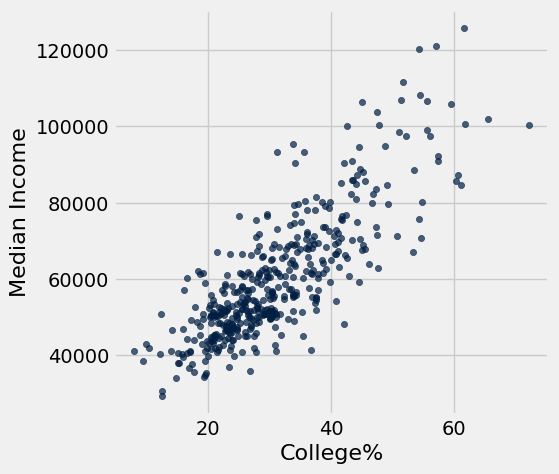

In [11]:
demographics.scatter('College%', 'Median Income')

In [65]:
college = demographics.column('College%')
income = demographics.column('Median Income')
print(f'''
College %     mean {np.average(college)}, and SD {np.std(college)}
Median Income mean {np.average(income)}, and SD {np.std(income)}

Correlation        {correlation(demographics, 'College%', 'Median Income')}
''')


College %     mean 30.88988505747126, and SD 10.536172557940397
Median Income mean 60054.40689655172, and SD 16357.85854678827

Correlation        0.8184648517141335



A strong positive association; fit the line and predict every district:

In [13]:
regression_slope = slope(demographics, 'College%', 'Median Income')
regression_intercept = intercept(demographics, 'College%', 'Median Income')
regression_slope, regression_intercept

 # Question: what are the units??

(1270.70168946388, 20802.577766677925)

In [66]:
# get regression estimate!

'''
def fitted_values(t, x, y):
    """Return an array of the regressions estimates at all the x values"""
    a = slope(t, x, y)
    b = intercept(t, x, y)
    return a*t.column(x) + b
'''

predicted = fitted_values(demographics, 'College%', 'Median Income')

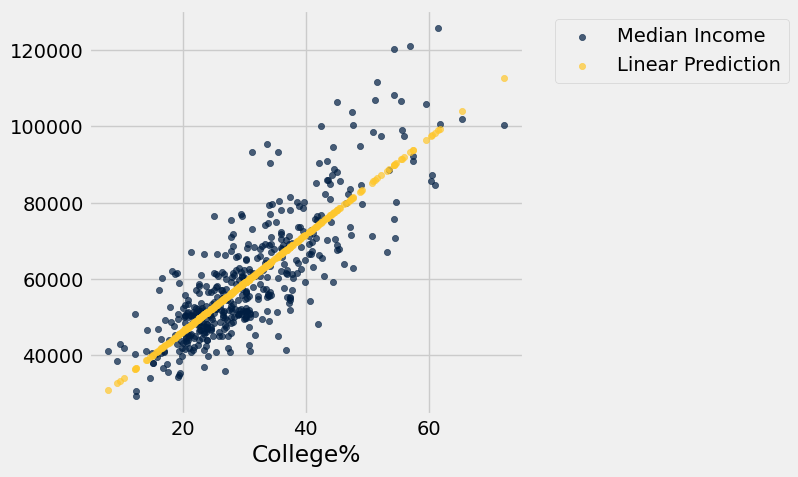

In [15]:
demographics = demographics.with_column(
    'Linear Prediction', predicted)
demographics.scatter('College%')

#### How WRONG are our regression estimates??

The error at each district: actual income minus the line's prediction:

In [16]:
actual = demographics.column('Median Income')
errors = actual - predicted

In [17]:
demographics.with_column('Error', errors)

Median Income,College%,Linear Prediction,Error
47083,24,51299.4,-4216.42
42035,21.8,48503.9,-6468.87
46544,22.8,49774.6,-3230.58
41110,17,42404.5,-1294.51
51690,30.3,59304.8,-7614.84
61413,36.7,67437.3,-6024.33
34664,19.4,45454.2,-10790.2
76440,29.6,58415.3,18024.7
50537,24.5,51934.8,-1397.77
49072,34,64006.4,-14934.4


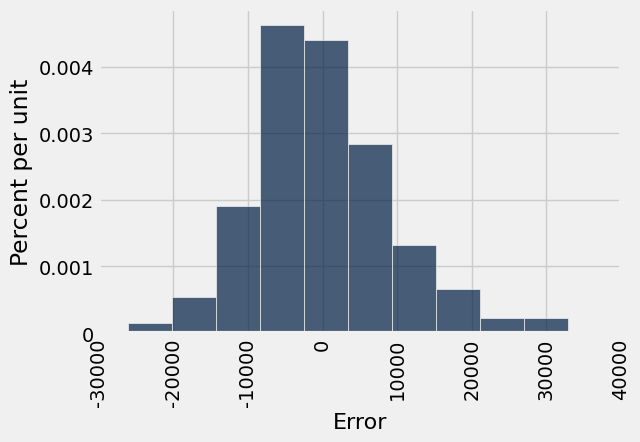

In [70]:
# Visualize the errors!

demographics.with_column('Error', errors).hist('Error')

Average all 435 errors: predict the result before you run it:

In [18]:
np.mean(errors)

6.3560089503211536e-13

How big is a typical error? Square the errors so they cannot cancel, average them (the mean squared error), then take the square root:

In [19]:
mse = np.mean(errors ** 2)
mse

88332095.268617392

In [20]:
rmse = mse ** 0.5
rmse

9398.5155885712811

Now see the errors as red sticks, for our line and then two deliberately bad lines:

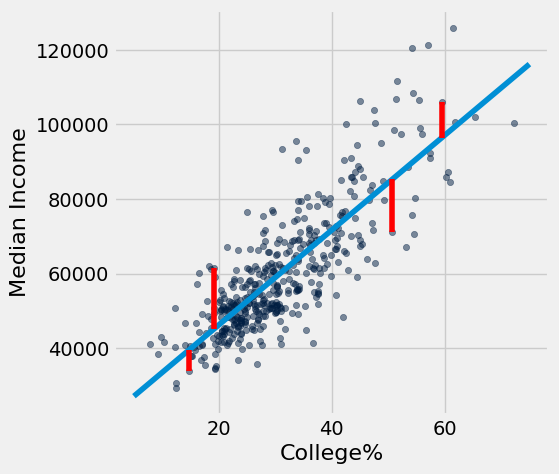

In [21]:
demographics_errors(regression_slope, regression_intercept)

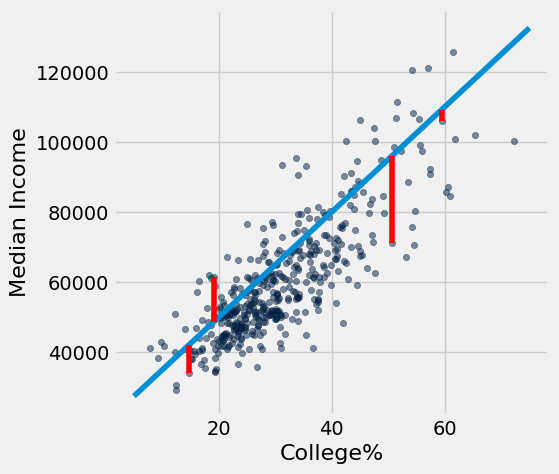

In [22]:
# takes any slope, any intercept
demographics_errors(1500, 20000)

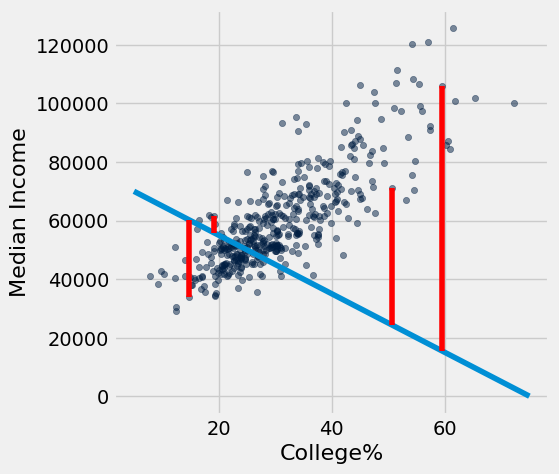

In [23]:
demographics_errors(-1000, 75000)

### Try It 1: Errors of a bad line 😊

1. Compute the errors for the line with slope 1500 and intercept 20000 (actual income minus that line's predictions), and find their mean.

2. Our regression line's errors averaged out to essentially zero. What does the sign of this line's mean error tell you?

In [24]:
# 1. mean error of the 1500 / 20000 line


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Any line makes errors; only the regression line balances them out to zero.*

```python
# 1.
bad_predictions = 1500 * demographics.column('College%') + 20000
bad_errors = actual - bad_predictions
np.mean(bad_errors)      # about -6280
```

*2. Negative mean: on average this line predicts about \$6,300 too high. A tilted or shifted line leaves leftover error that the regression line does not.*

</details>

---
## 3. Root Mean Square Error

One number for "how wrong is this line": square the errors (no canceling), average, square-root. Smaller RMSE = better line.

Root mean squared error: 30247.88


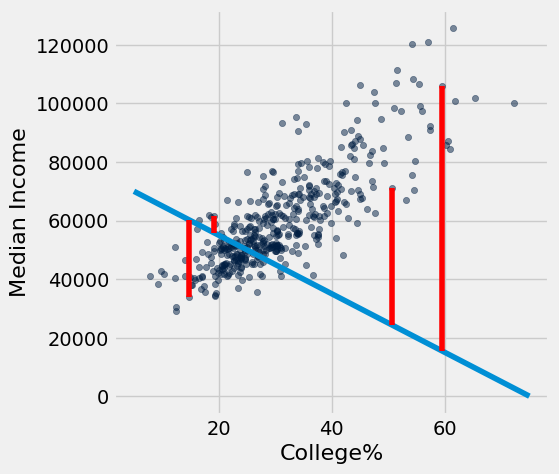

In [25]:
show_demographics_rmse(-1000, 75000)

Root mean squared error: 11559.09


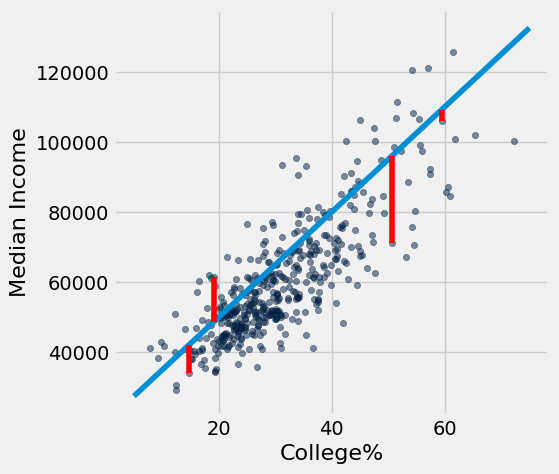

In [26]:
show_demographics_rmse(1500, 20000)

Root mean squared error: 9398.52


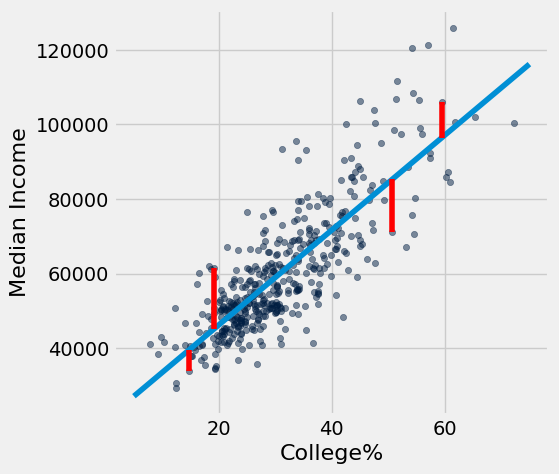

In [27]:
show_demographics_rmse(regression_slope, regression_intercept)

### Try It 2: Beat the bad lines 😈

1. Your choice: pick a slope and intercept and run `show_demographics_rmse` on them. Can you beat both bad lines above (RMSE under 11,559)? How close to the regression line's 9,398.5 can you get?

2. Do you think any line at all can score below 9,398.5? (Keep your answer; we will see in the next section.)

In [28]:
# 1. your line vs. the bad lines


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Many right answers; anything near the regression values scores close to 9,398.5.*

```python
# 1. one of many right answers
show_demographics_rmse(1300, 20000)      # RMSE about 9404: beats both bad lines
```

*2. No: Section 4 shows the regression line is the minimizer, so 9,398.5 is the floor.*

</details>

---
## 4. Numerical Optimization

How do we *know* no other line beats the regression line? `minimize(f)` finds the input that makes `f` smallest, watch it work on simple functions first.

### 📋 Reference Table

| Code | What it does |
|---|---|
| `minimize(f)` | input value(s) minimizing `f` |
| works on | any smooth function, any number of arguments |
| `demographics_rmse(slope, intercept)` | RMSE of *any* line |
| `minimize(demographics_rmse)` | the least-squares line! |

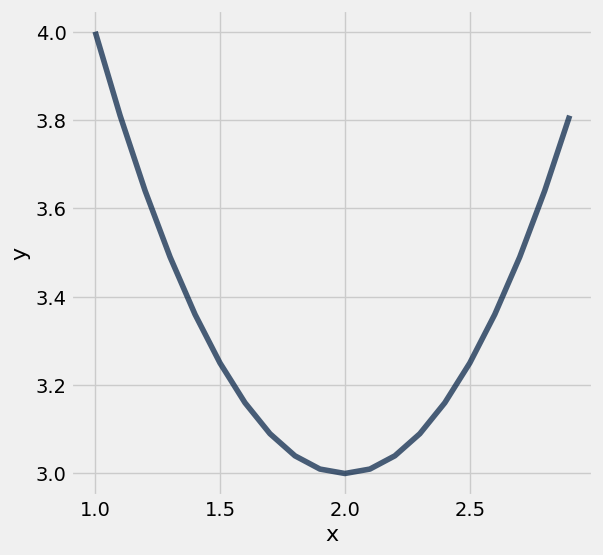

In [29]:
x = np.arange(1, 3, 0.1)
y = (x-2)**2 + 3
Table().with_columns('x', x, 'y', y).plot('x')

In [30]:
def f(x):
    return ((x-2)**2) + 3

In [31]:
minimize(f)

1.9999999946252267

A wigglier function next, but `minimize` does not care:

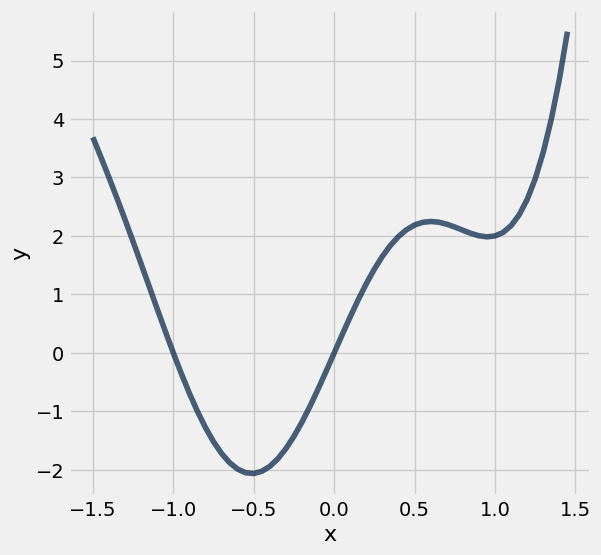

In [32]:
x = np.arange(-1.5, 1.5, 0.05)
y2 = 2 * np.sin(x*np.pi) + x ** 3 + x ** 4 
Table().with_columns('x', x, 'y', y2).plot('x')

In [33]:
def complicated_function(x):
    return 2 * np.sin(x*np.pi) + x ** 3 + x ** 4 

In [34]:
minimize(complicated_function)

-0.5126437620940081

### Minimizing RMSE

In [71]:
def demographics_rmse(any_slope, any_intercept):
    x = demographics.column('College%')
    y = demographics.column('Median Income')
    estimate = any_slope*x + any_intercept
    rmse = (np.mean((y - estimate) ** 2)) ** 0.5
    return rmse

In [36]:
demographics_rmse(1500, 20000)

11559.086490075999

In [37]:
demographics_rmse(-1000, 75000)

30247.883767944502

Now hand the whole two-argument function to `minimize` and let it search every possible line at once:

In [38]:
# minimizes the RMSE for ALL combos of slope and intercept!

minimize(demographics_rmse)

array([  1270.70168805,  20802.57933807])

Compare with the slope and intercept from our formulas:

In [39]:
make_array(regression_slope, regression_intercept)

array([  1270.70168946,  20802.57776668])

#### Minimize!

Optimal Slope: 1270.70
Optimal Intercept: 20802.58
Minimum RMSE: 9398.52


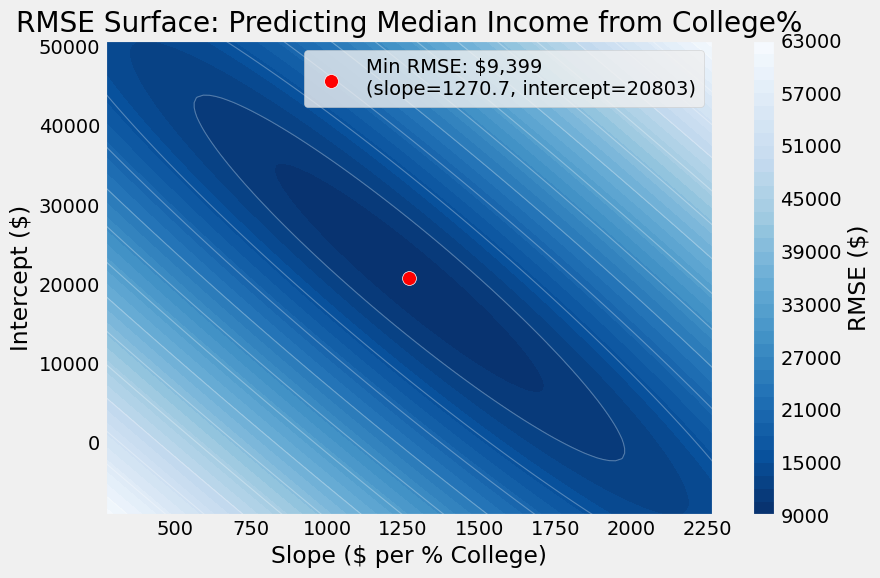

In [73]:
from datascience import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# 1. Load and prepare the Data 8 Table
demographics = Table.read_table('district_demographics2016.csv')
demographics = demographics.drop('State', 'District', 'Percent voting for Clinton')

x = demographics.column('College%')
y = demographics.column('Median Income')

# 2. Define the RMSE function using separate arguments (Data 8 style)
def demographics_rmse(slope, intercept):
    predicted = slope * x + intercept
    return np.sqrt(np.mean((y - predicted) ** 2))

# 3. Use Data 8's built-in minimize() function
best_params = minimize(demographics_rmse)
opt_slope = best_params.item(0)
opt_intercept = best_params.item(1)
min_rmse = demographics_rmse(opt_slope, opt_intercept)

print(f"Optimal Slope: {opt_slope:.2f}")
print(f"Optimal Intercept: {opt_intercept:.2f}")
print(f"Minimum RMSE: {min_rmse:.2f}")

# 4. Build a 2D grid of slope and intercept values around the minimum
slopes = np.linspace(opt_slope - 1000, opt_slope + 1000, 100)
intercepts = np.linspace(opt_intercept - 30000, opt_intercept + 30000, 100)
S, I = np.meshgrid(slopes, intercepts)

# Calculate RMSE for every (slope, intercept) pair on the grid
Z = np.array([[demographics_rmse(s, i) for s in slopes] for i in intercepts])

# 5. Plot the RMSE heatmap and mark the minimum
plt.figure(figsize=(9, 6))
heatmap = plt.contourf(S, I, Z, levels=35, cmap='Blues_r')
plt.colorbar(heatmap, label='RMSE ($)')

plt.contour(S, I, Z, levels=15, colors='white', alpha=0.3, linewidths=0.8)
plt.scatter(opt_slope, opt_intercept, color='red', s=100, edgecolor='white', zorder=5,
            label=f'Min RMSE: ${min_rmse:,.0f}\n(slope={opt_slope:.1f}, intercept={opt_intercept:.0f})')

plt.title('RMSE Surface: Predicting Median Income from College%')
plt.xlabel('Slope ($ per % College)')
plt.ylabel('Intercept ($)')
plt.legend()
plt.tight_layout()
plt.show()


> **The punchline:** `minimize` searched over *all* possible lines and landed on a slope and intercept that agree to many decimals with the ones from our formulas. The regression line isn't just *a* line, it's the provably best one (by RMSE).

### Try It 3: Minimize your own function 😊

1. Define `g(x)` that returns $(x - 7)^2 + 1$. Predict what `minimize(g)` will return, then run it.

2. Is that number the smallest *input* or the smallest *value* of `g`? Compute `g(minimize(g))` to see the actual minimum.

In [40]:
# 1. define g, then minimize it


In [41]:
# 2. g at the minimizing x


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*`minimize` returns the input that wins (the argmin), not the minimum value itself.*

```python
# 1.
def g(x):
    return (x - 7) ** 2 + 1

minimize(g)          # about 7, the minimizing input

# 2.
g(minimize(g))       # 1.0, the smallest value g can produce
```

</details>

---
## 5. Nonlinear Regression 🥇

`minimize` doesn't care about lines, hand it any function with parameters. Shot put distance vs. weight lifted looks *curved*, so let's fit a parabola.

In [42]:
shotput = Table.read_table('shotput.csv')
shotput

Weight Lifted,Shot Put Distance
37.5,6.4
51.5,10.2
61.3,12.4
61.3,13
63.6,13.2
66.1,13
70,12.7
92.7,13.9
90.5,15.5
90.5,15.8


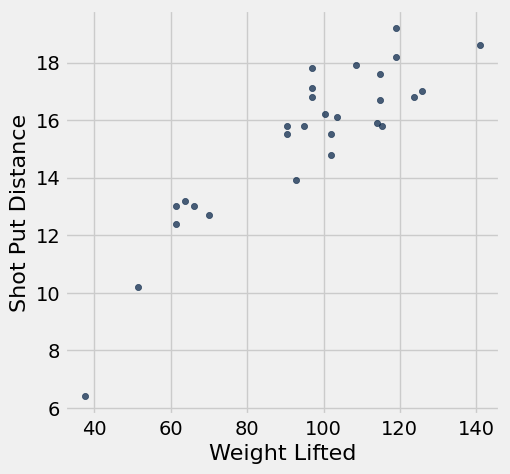

In [43]:
shotput.scatter('Weight Lifted')

Start with the best straight line, using the exact same RMSE recipe:

In [44]:
def shotput_linear_rmse(any_slope, any_intercept):
    x = shotput.column('Weight Lifted')
    y = shotput.column('Shot Put Distance')
    estimate = any_slope*x + any_intercept
    return np.mean((y - estimate) ** 2) ** 0.5

In [45]:
best_line = minimize(shotput_linear_rmse)
best_line

array([ 0.09834382,  5.95962883])

Overlay that line on the scatter:

In [46]:
weights = shotput.column(0)

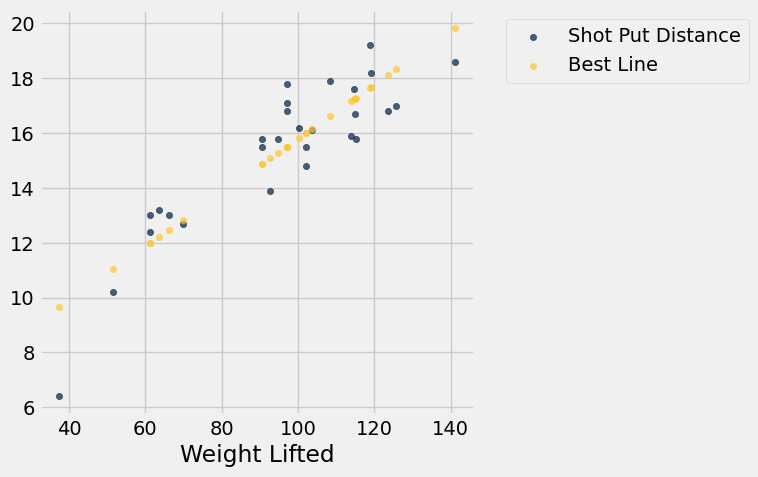

In [47]:
linear_fit = best_line.item(0)*weights + best_line.item(1)

shotput.with_column(
    'Best Line', linear_fit
).scatter(0)

**Quadratic Function**

$$
f(x) ~=~ ax^2 + bx + c
$$
for constants $a$, $b$, and $c$.



In [48]:
def shotput_quadratic_rmse(a, b, c):
    x = shotput.column('Weight Lifted')
    y = shotput.column('Shot Put Distance')
    estimate = a*(x**2) + b*x + c
    return np.mean((y - estimate) ** 2) ** 0.5

In [49]:
best_quad = minimize(shotput_quadratic_rmse)
best_quad

array([ -1.04003731e-03,   2.82706003e-01,  -1.53167618e+00])

### Try It 4: Predict with the parabola 😊

1. Using `best_quad`, predict the shot put distance of an athlete who lifts 100 kg. (The code cell after the answers shows it with hard-coded constants; write it with `best_quad.item(...)` instead.)

In [50]:
# 1. quadratic prediction at x = 100


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

```python
# 1.
best_quad.item(0)*(100**2) + best_quad.item(1)*100 + best_quad.item(2)   # ≈ 16.3 meters
```

</details>

In [51]:
# x = weight lifted = 100 kg
# Then predicted shot put distance:

(-0.00104)*(100**2) + 0.2827*100 - 1.5318

16.3382

Now compute the curve at every weight in the data and draw it:

In [52]:
quad_fit = best_quad.item(0)*(weights**2) + best_quad.item(1)*weights + best_quad.item(2)

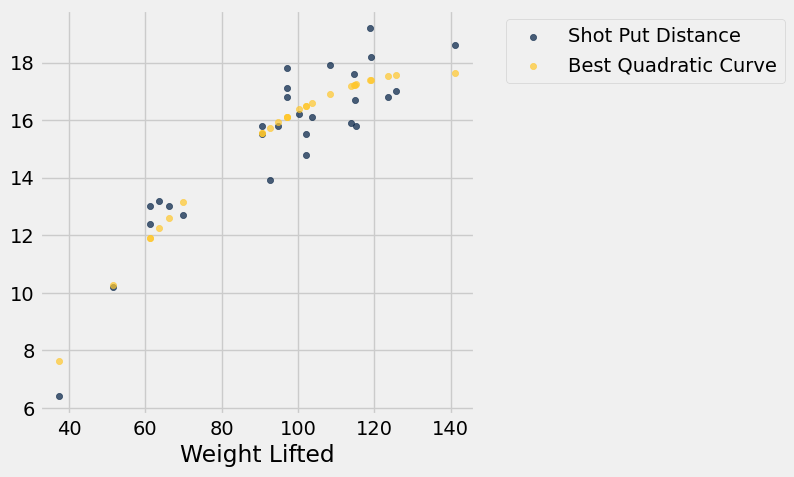

In [53]:
shotput.with_column('Best Quadratic Curve', quad_fit).scatter(0)

Which model fits better? Compare the RMSE of the best quadratic curve and the best line:

In [54]:
shotput_quadratic_rmse(best_quad.item(0), best_quad.item(1), best_quad.item(2))

0.98188452305971619

In [55]:
shotput_linear_rmse(best_line.item(0), best_line.item(1))

1.2194444845058761

---
> **Today's takeaway:** "best line" means least RMSE; `minimize` proves the regression formulas optimal; and the same machinery fits curves when the data bends. Homework 9's sea-level fits use exactly this.

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### Minimal template — fit anything
```python
def my_rmse(a, b):
    estimate = a * x + b            # or a*x**2 + b*x + c ...
    return np.mean((y - estimate) ** 2) ** 0.5

minimize(my_rmse)
```